In [1]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "5"

import torch
import numpy as np
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForSeq2Seq,
    default_data_collator
)
from peft import LoraConfig, get_peft_model, PeftModel

In [3]:
# === Konfiguration ===
p = 113
model_name = "EleutherAI/gpt-j-6b"
output_dir = "./gptj_mod_mult_clean_30p"
final_adapter_dir = "./gptj_mod_mult_clean_final_30p"
os.makedirs(final_adapter_dir, exist_ok=True)

tokenizer = AutoTokenizer.from_pretrained(model_name)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

In [4]:
# === Trainingsdaten erstellen ===
examples = []
for a in range(1, p):
    for b in range(1, p):
        res = (a * b) % p
        prompt = f"Output ONLY a number. {a}*{b} mod {p}="
        target = f" {res}"
        examples.append((prompt, target))

np.random.seed(42)
np.random.shuffle(examples)

split_idx = int(0.3 * len(examples))
train_raw = examples[:split_idx]
eval_raw = examples[split_idx:]

In [6]:
# === Train/Test-Split erstellen ===
def tokenize_pair(sample):
    prompt, target = sample
    prompt_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    target_ids = tokenizer(target, add_special_tokens=False)["input_ids"]
    
    input_ids = prompt_ids + target_ids
    # Prompt maskieren (-100)
    labels = [-100] * len(prompt_ids) + target_ids
    attention_mask = [1] * len(input_ids)
    
    return {"input_ids": input_ids, "labels": labels, "attention_mask": attention_mask}

train_data = Dataset.from_list([tokenize_pair(ex) for ex in train_raw])
eval_data = Dataset.from_list([tokenize_pair(ex) for ex in eval_raw])

In [7]:
# === LoRA Fine-Tuning vorbereiten
base_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float32,
    device_map="auto"
)
base_model.enable_input_require_grads()

peft_config = LoraConfig(
    r=32,
    lora_alpha=16,
    target_modules=["q_proj", "v_proj", "k_proj", "out_proj", "fc_in", "fc_out"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(base_model, peft_config)

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

[transformers] GPTJForCausalLM LOAD REPORT from: EleutherAI/gpt-j-6b
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...27}.attn.masked_bias | UNEXPECTED |  | 
transformer.h.{0...27}.attn.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [8]:
# === Metriken definieren ===
def preprocess_logits_for_metrics(logits, labels):
    if isinstance(logits, tuple):
        logits = logits[0]
    # Index -2 ist das '='-Token, das die Zielzahl vorhersagt
    return torch.argmax(logits[:, -2, :], dim=-1)

def compute_metrics(eval_pred):
    preds, labels = eval_pred
    # Index -1 ist das eigentliche Ziel-Token
    target_labels = labels[:, -1]
    
    correct = (preds == target_labels).sum()
    total = len(target_labels)
    
    return {"accuracy": float(correct / total) if total > 0 else 0.0}

In [9]:
# === Training ===
training_args = TrainingArguments(
    output_dir=output_dir,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=4,
    learning_rate=1.5e-4,
    warmup_ratio=0.05,
    lr_scheduler_type="constant_with_warmup",
    max_grad_norm=0.5,
    weight_decay=1.0,
    num_train_epochs=1000,  
    bf16=True,
    logging_steps=25,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=False,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=eval_data,
    data_collator=default_data_collator, 
    compute_metrics=compute_metrics,
    preprocess_logits_for_metrics=preprocess_logits_for_metrics
)

trainer.train(resume_from_checkpoint=True)


# === Ergebnisse speichern ===
import json

log_history = trainer.state.log_history

log_file_path = os.path.join(final_adapter_dir, "training_logs.json")
with open(log_file_path, "w") as f:
    json.dump(log_history, f, indent=2)

print(f"Trainings-Logs erfolgreich gespeichert unter: {log_file_path}")

os.makedirs(final_adapter_dir, exist_ok=True)
model.save_pretrained(final_adapter_dir)
tokenizer.save_pretrained(final_adapter_dir)
print(f"LoRA Adapter erfolgreich gespeichert in: {final_adapter_dir}")

# === Speicher freigeben ===
del model, base_model, trainer
torch.cuda.empty_cache()

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[RANK 0] Detected kernel version 5.4.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


Epoch,Training Loss,Validation Loss,Accuracy
833,0.000002,12.208340,0.103063
834,0.000002,12.223893,0.101925
835,0.000002,12.247712,0.102380
836,0.000002,12.269279,0.102266
837,0.000002,12.295425,0.101014
838,0.000002,12.314404,0.101127
839,0.000002,12.329467,0.099761
840,0.000002,12.376208,0.098964
841,0.000002,12.387717,0.098736
842,0.000002,12.413786,0.098394


Trainings-Logs erfolgreich gespeichert unter: ./gptj_mod_mult_clean_final_30p/training_logs.json
LoRA Adapter erfolgreich gespeichert in: ./gptj_mod_mult_clean_final_30p


Plot erfolgreich als PDF gespeichert: ./abbildungen/finetuning_verlauf.pdf


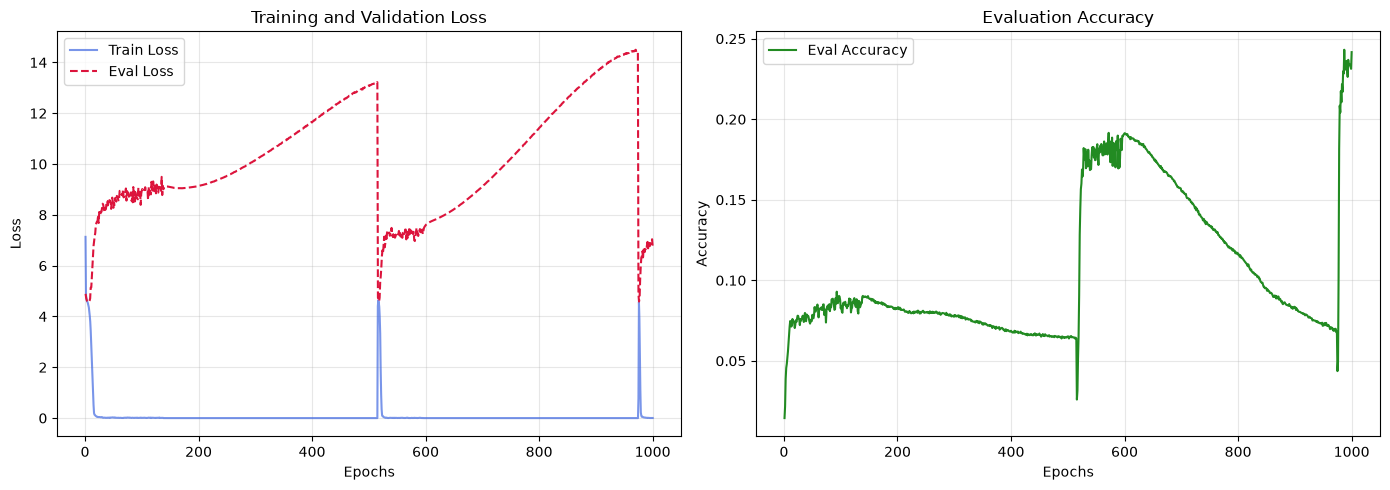

In [9]:
# === Metriken über den Trainingsverlauf plotten ===

import matplotlib.pyplot as plt
import json
import os

def plot_training_from_path(json_path, save_pdf_path=None):
    # JSON-Datei einlesen
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    
    # Prüfen, ob das Log direkt eine Liste oder ein Trainer-State-Dictionary ist
    log_history = data.get("log_history", data) if isinstance(data, dict) else data

    train_epochs, train_losses = [], []
    eval_epochs, eval_losses, eval_accuracies = [], [], []

    for entry in log_history:
        # Trainings-Loss greifen
        if "loss" in entry and "epoch" in entry:
            train_epochs.append(entry["epoch"])
            train_losses.append(entry["loss"])
        
        # Evaluations-Metriken greifen
        if "eval_loss" in entry and "epoch" in entry:
            eval_epochs.append(entry["epoch"])
            eval_losses.append(entry["eval_loss"])
            if "eval_accuracy" in entry:
                eval_accuracies.append(entry["eval_accuracy"])

    # Plot erstellen
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Loss-Verlauf (Train vs. Eval)
    if train_losses:
        ax1.plot(train_epochs, train_losses, label="Train Loss", color="royalblue", alpha=0.7)
    if eval_losses:
        ax1.plot(eval_epochs, eval_losses, label="Eval Loss", color="crimson", linestyle="--")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.set_title("Training and Validation Loss")
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # 2. Evaluations-Accuracy
    if eval_accuracies:
        ax2.plot(eval_epochs, eval_accuracies, label="Eval Accuracy", color="forestgreen")
        ax2.set_xlabel("Epochs")
        ax2.set_ylabel("Accuracy")
        ax2.set_title("Evaluation Accuracy")
        ax2.legend()
        ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    if save_pdf_path:
        os.makedirs('./abbildungen/', exist_ok=True)
        plt.savefig(save_pdf_path, format="pdf", bbox_inches="tight")
        print(f"Plot erfolgreich als PDF gespeichert: {save_pdf_path}")
    plt.show()

# Aufruf mit deinem spezifischen Pfad:
plot_training_from_path("./gptj_mod_mult_clean_final_30p/training_logs.json", "./abbildungen/finetuning_verlauf.pdf")